# Workflow study: DMRG → MPS-to-circuit → filter on the 1D $J_1$-$J_2$ chain

**Model.** Open chain $H = J_1\sum_i \mathbf S_i\cdot\mathbf S_{i+1} + J_2\sum_i \mathbf S_i\cdot\mathbf S_{i+2}$, $J_2 = 0.2411$, **no dimerisation**: the gap and the
spectral width are whatever the chain has at each $N$, so $\eta(N) = \Delta/W$ shrinks with $N$.

**Pipeline per N.** DMRG spectral estimates ($E_0$; $E_1$ from DMRG with a penalty that pushes the ground-state sector up; $E_{\max}$ from DMRG on $-H$) and DMRG ground state → 1-layer MPS-to-circuit ([qiskit-community/mps-to-circuit](https://github.com/qiskit-community/mps-to-circuit)) → trial state with its natural overlap $\gamma_0(N)$ → filter → post-selected ground state with $1-F\le\epsilon$.

**Methods** (all apply the same filter polynomial $F = \prod_{k<K}\cos(2^k\tau H_s)^r$, $H_s=(H-E_0)/W$, $\tau=\pi/(1+\eta)$, built from second-order Strang steps):

| method | qubits | how success is reached |
|---|---|---|
| SBC (RUS) | $N+1$ | one ancilla, measured and reset after each pulse; repeat until success, $1/p$ attempts |
| SBC + AA | $N+Kr$ | one ancilla per pulse (no mid-circuit measurement), $k\approx\pi/4\sqrt p$ Grover rounds |
| QETU (RUS) | $N+1$ | one ancilla, $d=r(2^K-1)$ controlled steps interleaved with $d+1$ ancilla $R_x(\phi_j)$ |
| QETU + AA | $N+1$ | QETU inside AA; $R_{good}$ is a single-qubit $Z$ |

**Simulation.** Standard Qiskit Aer statevector simulation of the circuits themselves, on all $2^{N+1}$ amplitudes: the trial-prep circuit from `mps_to_circuit`, then the Trotterised filter pulses. Post-selection on the ancilla is done on the saved statevector after each pulse (RUS: measure the ancilla, keep 0, reset). QETU at the chosen setting is built with its solved phases and run in Aer as a check: it applies the same polynomial to the same Strang step, so its $p$ and $1-F$ match SBC's. Fidelity is measured against the exact (ED) ground state.

**Costs.** CNOTs and non-Clifford $R_z$ (angle not a multiple of $\pi/2$) after compiling to {CX, Rz, SX, X}. Per method, $(K, r, n)$ is chosen to minimise the CNOTs per success **including trial preparation**, with $\tau$ and $H_s$ set from the DMRG estimates, with $1-F\le\epsilon$ required at $n$ and at the next finer $n$ (no lucky Trotter cancellations). AA cost uses $\sin^2((2k+1)\theta)$ with the simulated $p$ (AA assumes $p$ is known).

In [1]:
# ---- parameters
NS       = [6, 8, 10, 12, 14, 16]       # chain lengths
J1, J2   = 1.0, 0.2411
EPS      = 1e-2                         # target infidelity of the post-selected state
N_GRID   = [1, 2, 3, 4, 6, 8]           # Strang steps per τ tried
K_MAX, R_MAX = 8, 6
DMRG_BONDS = [16, 32, 64, 128]

import os, sys, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, os.path.abspath("."))                       # run from ORNL/
from ornl import Chain                                         # ED reference only (fidelity, DMRG errors)
import quimb.operator as qop, quimb.tensor as qtn
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator                            # pip install qiskit-aer
from scipy.optimize import least_squares
from mps_to_circuit import mps_to_circuit                         # pip install --ignore-requires-python mps-to-circuit
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

## 1. Gate-count model and its check against real Qiskit circuits

Controlled bond $e^{-i\phi(XX+YY+ZZ)Z_a}$: Clifford Bell change + 4-CNOT parity network = **6 CNOT, 3 non-Clifford Rz**. A controlled run of $m$ merged Strang steps has $(2B-2)m+1$ bond blocks ($B=2N-3$ bonds) plus one ancilla Rz for the $-E_0/W$ part.
SBC merges the steps inside each pulse; QETU cannot merge across its $R_x(\phi_j)$, so each of its $d$ calls is a separate run of $n$ steps. Multi-controlled Z for the AA reflections is counted from Qiskit's synthesis. The model is a slight upper bound: Qiskit's transpiler cancels about 6% of the CNOTs between neighbouring blocks (see the check below).

In [2]:
CLIFF = lambda x: abs(x / (np.pi / 2) - round(x / (np.pi / 2))) < 1e-9

def counts(qc):
    t = transpile(qc, basis_gates=["cx", "rz", "sx", "x"], optimization_level=1)
    rz = [float(g.operation.params[0]) for g in t.data if g.operation.name == "rz"]
    return np.array([t.count_ops().get("cx", 0), sum(not CLIFF(x) for x in rz)])

def blocks(N, m):                     # bond blocks in m merged Strang steps
    return (2 * (2 * N - 3) - 2) * m + 1

def sbc_attempt(N, K, r, n):          # (CNOT, non-Clifford Rz) of one SBC attempt (K r pulses)
    b = sum(blocks(N, n * 2 ** k) for k in range(K)) * r
    return np.array([6 * b, 3 * b + K * r])

def qetu_attempt(N, K, r, n):         # d controlled n-step runs + (d + 1) ancilla Rx
    d = r * (2 ** K - 1)
    return np.array([6 * d * blocks(N, n), d * (3 * blocks(N, n) + 1) + d + 1])

_mcz = {}
def mcz(nq):                          # sign flip of |0...0> on nq qubits
    if nq not in _mcz:
        qc = QuantumCircuit(nq); qc.x(range(nq))
        if nq == 1: qc.z(0)
        else: qc.h(nq - 1); qc.mcx(list(range(nq - 1)), nq - 1); qc.h(nq - 1)
        qc.x(range(nq)); _mcz[nq] = counts(qc)
    return _mcz[nq]

# ---- check the model on real circuits (N = 6, K = 2, r = 2, n = 2)
def bond_block(qc, i, j, a, phi):
    qc.cx(i, j); qc.h(i)
    qc.cx(i, a); qc.rz(2 * phi, a); qc.cx(j, a); qc.rz(-2 * phi, a); qc.cx(i, a); qc.rz(2 * phi, a); qc.cx(j, a)
    qc.h(i); qc.cx(i, j)
def ctrl_run(qc, ch, a, t, steps):
    one = list(range(len(ch.bonds))) + list(range(len(ch.bonds)))[::-1]; seq = []
    for b in one * steps:
        if seq and seq[-1][0] == b: seq[-1][1] += 1
        else: seq.append([b, 1])
    for b, w in seq:
        i, j, J = ch.bonds[b]; bond_block(qc, i, j, a, w * (t / steps / 2) * J / (4 * ch.W))
    qc.rz(-2 * t * ch.E0 / ch.W, a)
ch6, K_, r_, n_ = Chain(6, 0.0, J1, J2), 2, 2, 2
tau6 = np.pi / (1 + ch6.gap_s)
sbc = QuantumCircuit(7)
for _ in range(r_):
    for k in range(K_):
        sbc.h(6); ctrl_run(sbc, ch6, 6, 2 ** k * tau6, 2 ** k * n_); sbc.h(6)
qetu = QuantumCircuit(7); rng = np.random.default_rng(1); qetu.rx(rng.normal(), 6)
for _ in range(r_ * (2 ** K_ - 1)):
    ctrl_run(qetu, ch6, 6, tau6, n_); qetu.rx(rng.normal(), 6)
print("                 model (CNOT, Rz)   Qiskit transpiled (CNOT, Rz)")
print(f"SBC  attempt     {tuple(sbc_attempt(6, K_, r_, n_))}        {tuple(counts(sbc))}")
print(f"QETU attempt     {tuple(qetu_attempt(6, K_, r_, n_))}        {tuple(counts(qetu))}")
print("MCZ (CNOT, Rz) by qubit count: " + ", ".join(f"{q}: {tuple(mcz(q))}" for q in (2, 5, 10, 20, 40)))

                 model (CNOT, Rz)   Qiskit transpiled (CNOT, Rz)
SBC  attempt     (np.int64(1176), np.int64(592))        (np.int64(1102), np.int64(592))
QETU attempt     (np.int64(1188), np.int64(607))        (np.int64(1110), np.int64(607))
MCZ (CNOT, Rz) by qubit count: 2: (np.int64(1), np.int64(0)), 5: (np.int64(36), np.int64(43)), 10: (np.int64(290), np.int64(303)), 20: (np.int64(1370), np.int64(1403)), 40: (np.int64(4746), np.int64(3998))


## 2. Per N: ED reference, DMRG, 1-layer MPS-to-circuit trial

ED gives the exact reference, used only to measure fidelity and the DMRG errors. DMRG gives the spectral estimates that set the filter: $E_0$ from DMRG on $H$, $E_{\max}$ from DMRG on $-H$, and $E_1$ from DMRG with a penalty $\lambda(S^z_{tot}-1)^2$, which lands on the lowest triplet (the first excited level) without using the DMRG ground state, so the ground state's error does not carry into $E_1$.

The trial is the package default, `mps_to_circuit(..., method="approximate", num_layers=1)` on the DMRG ground state, run in Aer. Its bond-2 compression is a plain SVD that ignores $S^z$, so a little weight leaves $S^z=0$ (`leak_out_of_Sz0`). $H$ conserves $S^z$ and every level outside $S^z=0$ is at or above $E_1$, so the filter removes that weight like any other excited-state weight; it just lowers $\gamma_0$. The Aer simulation keeps all of it.

In [3]:
def dmrg(N, sign=1.0, penalty=None):
    bonds = [(i, i + 1, J1) for i in range(N - 1)] + [(i, i + 2, J2) for i in range(N - 2)]
    Jd = {(i, j): sign * J for i, j, J in bonds}
    b = qop.heisenberg_from_edges(list(Jd), j=lambda i, j: Jd[(i, j)] if (i, j) in Jd else Jd[(j, i)])
    if penalty:                       # penalty (S^z_tot - 1)^2: the S^z = 0 ground state is pushed up, the triplet is not
        for i in range(N):
            for j in range(N):
                if i != j:
                    b.add_term(penalty, ("sz", i), ("sz", j))
            b.add_term(-2 * penalty, ("sz", i))
    d = qtn.DMRG2(b.build_mpo(), bond_dims=DMRG_BONDS, cutoffs=1e-12); d.solve(tol=1e-10, verbosity=0, max_sweeps=40)
    E = float(np.real(d.energy)) + (penalty * (N / 4 + 1) if penalty else 0.0)   # constant part of the penalty
    return E, d.state

def dmrg_ground_state(N):
    return dmrg(N)

SIM = AerSimulator(method="statevector")

def aer_state(qc, init=None):
    # run qc in Aer from |0...0> or from the normalised statevector init; return the final statevector
    c = QuantumCircuit(qc.num_qubits)
    if init is not None:
        c.set_statevector(init)
    c.compose(qc, inplace=True); c.save_statevector()
    return np.asarray(SIM.run(c).result().get_statevector())

def to_qiskit(ch, v):                 # ED sector vector -> 2^N vector, qubit i = site i
    q = sum((((ch.states >> (ch.N - 1 - i)) & 1) << i) for i in range(ch.N))
    out = np.zeros(1 << ch.N, complex); out[q] = v
    return out

def sz0_weight(v, N):
    pc = np.array([bin(i).count("1") for i in range(1 << N)])
    return float(np.sum(abs(v[pc == N // 2]) ** 2))

class Est:                            # what the filter is allowed to know: DMRG estimates and the bonds
    pass

chains, prep = {}, []
for N in NS:
    t0 = time.time()
    ed = Chain(N, 0.0, J1, J2)                                   # exact reference
    g0 = to_qiskit(ed, ed.g0)
    E0_d, psi = dmrg_ground_state(N)
    mps = psi.copy(); mps.permute_arrays("lrp")
    qc = mps_to_circuit(list(mps.arrays), method="approximate", shape="lrp", num_layers=1)
    trial = aer_state(qc)
    E1_d, Emax_d = dmrg(N, penalty=2.0)[0], -dmrg(N, sign=-1.0)[0]
    ch = Est()
    ch.N, ch.bonds, ch.g0, ch.trial = N, ed.bonds, g0, trial
    ch.E0, ch.E1, ch.Emax = E0_d, E1_d, Emax_d
    ch.gap, ch.W = E1_d - E0_d, Emax_d - E0_d
    ch.gap_s = ch.gap / ch.W
    ch.gamma0 = abs(np.vdot(g0, trial)) ** 2
    ch.prep = counts(qc)
    chains[N] = ch
    prep.append(dict(N=N, E0=ch.E0, dmrg_E0_err=abs(E0_d - ed.E0), dmrg_E1_err=abs(E1_d - ed.E1),
                     dmrg_Emax_err=abs(Emax_d - ed.Emax), dmrg_eta_err=abs(ch.gap_s - ed.gap_s), gap=ch.gap, W=ch.W,
                     eta=ch.gap_s, gamma0=ch.gamma0, leak_out_of_Sz0=1 - sz0_weight(trial, N),
                     prep_CNOT=ch.prep[0], prep_nonCliff_Rz=ch.prep[1], seconds=time.time() - t0))
prep = pd.DataFrame(prep).set_index("N")
display(prep.style.format({"E0": "{:.6f}", "dmrg_E0_err": "{:.1e}", "dmrg_E1_err": "{:.1e}", "dmrg_Emax_err": "{:.1e}",
                           "dmrg_eta_err": "{:.1e}", "gap": "{:.4f}", "W": "{:.4f}", "eta": "{:.5f}", "gamma0": "{:.4f}",
                           "leak_out_of_Sz0": "{:.1e}", "seconds": "{:.1f}"}))


,E0,dmrg_E0_err,dmrg_E1_err,dmrg_Emax_err,dmrg_eta_err,gap,W,eta,gamma0,leak_out_of_Sz0,prep_CNOT,prep_nonCliff_Rz,seconds
N,,,,,,,,,,,,,
6,-2.335347,4.4e-16,1.2e-13,4.4e-16,3.2e-14,0.4878,3.8264,0.12748,0.9494,1.4e-02,11,26,0.4
8,-3.135001,4.4e-16,2.6e-14,2.2e-15,4.9e-15,0.3859,5.2467,0.07355,0.9111,2.6e-02,18,36,0.2
10,-3.936128,2.8e-12,8.0e-12,1.8e-15,8.1e-13,0.3191,6.6683,0.04785,0.8690,2.1e-02,24,46,0.4
12,-4.738077,1.0e-11,5.6e-12,2.7e-13,5.2e-13,0.2720,8.0908,0.03362,0.8252,1.0e-02,29,56,0.8
14,-5.540531,2.3e-11,1.2e-11,1.3e-12,1.2e-12,0.2370,9.5138,0.02491,0.7810,6.7e-03,30,66,2.9
16,-6.343316,3.1e-11,2.8e-11,3.6e-12,2.2e-13,0.2100,10.9372,0.01920,0.7373,9.3e-02,35,76,7.7


## 3. Cheapest filter per method and N (Aer)

For each $n$, each pulse $H\,[\text{controlled } e^{-i2^k\tau H_s Z_a} \text{ with } 2^k n \text{ Strang steps}]\,H$ is built once and run in Aer on the current state; the ancilla is post-selected on 0 after each pulse and $p$ is the product of the pulse probabilities. Pulses commute (all are functions of the same Strang step), so for each $r$ the state is grown one $K$ at a time. For each $r$ the smallest passing $K$ is kept (a larger $K$ only costs more), and a choice counts only if the same $(K, r)$ also passes at the next $n$. $n$ is raised until a level brings no cheaper choice for any method. AA uses $k = \mathrm{round}(\pi/4\theta - 1/2)$ and $\sin^2((2k+1)\theta)$ with the simulated $p$.

In [4]:
METHODS = ["SBC", "SBC+AA", "QETU", "QETU+AA"]

def method_cost(N, K, r, n, p, prep_c, best_so_far):
    # cost per success of each method (trial prep inside every attempt); AA only where a Grover round helps
    s_att, q_att = sbc_attempt(N, K, r, n) + prep_c, qetu_attempt(N, K, r, n) + prep_c
    s_flt, q_flt = sbc_attempt(N, K, r, n), qetu_attempt(N, K, r, n)
    out = dict(SBC=dict(run=s_att, flt=s_flt, P=p, k=0, qubits=N + 1), QETU=dict(run=q_att, flt=q_flt, P=p, k=0, qubits=N + 1))
    th = np.arcsin(np.sqrt(p)); k = max(0, int(round(np.pi / (4 * th) - 0.5))); P = np.sin((2 * k + 1) * th) ** 2
    for name, att, flt, refl, nq in (("SBC+AA", s_att, s_flt, lambda: mcz(K * r) + mcz(N + K * r), N + K * r),
                                     ("QETU+AA", q_att, q_flt, lambda: mcz(1) + mcz(N + 1), N + 1)):
        plain = dict(out[name.split("+")[0]])
        if k >= 1 and (2 * k + 1) * float(att[0]) / P < min(best_so_far.get(name, np.inf), float(att[0]) / p):
            R = refl()
            out[name] = dict(run=(2 * k + 1) * att.astype(float) + k * R, flt=(2 * k + 1) * flt.astype(float) + k * R,
                             P=P, k=k, qubits=nq)
        else:
            out[name] = plain
    for v in out.values():
        v["tot"], v["filt"] = np.asarray(v["run"], float) / v["P"], np.asarray(v["flt"], float) / v["P"]
    return out

_pulses = {}
def pulse(ch, k, n):                  # H, controlled e^{-i 2^k τ H_s Z_a} with 2^k n merged Strang steps, H
    key = (ch.N, k, n)
    if key not in _pulses:
        qc = QuantumCircuit(ch.N + 1); qc.h(ch.N)
        ctrl_run(qc, ch, ch.N, 2 ** k * np.pi / (1 + ch.gap_s), 2 ** k * n); qc.h(ch.N)
        _pulses[key] = qc
    return _pulses[key]

def apply_pulse(ch, v, k, n):         # v: normalised system state; returns post-selected normalised state and p_k
    out = aer_state(pulse(ch, k, n), np.kron([1, 0], v))[: 1 << ch.N]      # ancilla = qubit N = most significant
    pk = np.vdot(out, out).real
    return out / np.sqrt(pk), pk

def run_filter(ch, K, r, n):          # (p, 1 - F) of the dyadic filter run gate by gate in Aer
    v, p = ch.trial, 1.0
    for _ in range(r):
        for k in range(K):
            v, pk = apply_pulse(ch, v, k, n); p *= pk
    return p, 1 - abs(np.vdot(ch.g0, v)) ** 2

def scan(ch, n, best_cost):
    # for each r: grow K until 1 - F <= EPS; returns {(K, r): (p, 1 - F)} for the passing (smallest-K) choices
    out = {}
    for r in range(1, R_MAX + 1):
        if r * sbc_attempt(ch.N, 1, 1, n)[0] > best_cost:              # even K = 1 at this r costs more than the best
            break
        v, p = ch.trial, 1.0
        for K in range(1, K_MAX + 1):
            for _ in range(r):
                v, pk = apply_pulse(ch, v, K - 1, n); p *= pk
            inf = 1 - abs(np.vdot(ch.g0, v)) ** 2
            if inf <= EPS:
                out[(K, r)] = (p, inf); break
            if p < 1e-8 or sbc_attempt(ch.N, K + 1, r, n)[0] > best_cost:
                break
    return out

rows = []
for N in NS:
    ch, t0 = chains[N], time.time()
    best, prev = {}, None
    for i, n in enumerate(N_GRID):
        cur = min([b["tot"][0] for b in best.values()], default=np.inf)
        found = scan(ch, n, 3 * cur)                                     # 3x: QETU and AA costs differ from SBC's
        improved = False
        if prev is not None:
            n_prev, cand = prev
            for (K, r), (p, inf) in sorted(cand.items()):
                p2, inf2 = found[(K, r)] if (K, r) in found else run_filter(ch, K, r, n)
                if inf2 > EPS:
                    continue
                costs_now = {m: best[m]["tot"][0] for m in best}
                for name, x in method_cost(N, K, r, n_prev, p, ch.prep, costs_now).items():
                    if name not in best or x["tot"][0] < best[name]["tot"][0]:
                        best[name] = dict(x, K=K, r=r, n=n_prev, p=p, infid=inf); improved = True
            if i >= 2 and not improved and len(best) == len(METHODS):
                break
        prev = (n, found)
    for name in METHODS:
        b = best[name]
        rows.append(dict(N=N, method=name, eta=ch.gap_s, gamma0=ch.gamma0, K=b["K"], r=b["r"], n=b["n"],
                         d=b["r"] * (2 ** b["K"] - 1), qubits=b["qubits"], AA_k=b["k"], p=b["p"], P_run=b["P"],
                         infid=b["infid"], CNOT_run=b["run"][0], Rz_run=b["run"][1],
                         CNOT_per_success=b["tot"][0], Rz_per_success=b["tot"][1],
                         filter_CNOT_per_success=b["filt"][0], filter_Rz_per_success=b["filt"][1]))
    print(f"N = {N}: done in {time.time() - t0:.0f} s (n up to {n})")
res = pd.DataFrame(rows)
res.to_csv("results/workflow_study.csv", index=False); prep.to_csv("results/workflow_prep.csv")


N = 6: done in 1 s (n up to 3)


N = 8: done in 2 s (n up to 3)


N = 10: done in 8 s (n up to 3)


N = 12: done in 25 s (n up to 3)


N = 14: done in 63 s (n up to 3)


N = 16: done in 146 s (n up to 3)


### QETU check in Aer

At each $N$, the QETU circuit for the chosen $(K, r, n)$ is built with its phases ($\langle 0|U_\Phi|0\rangle = \prod_k T_{2^k}(x)^r$, solved by least squares from $\phi = (\pi/4, 0, \dots, 0, \pi/4)$) and run in Aer: $N+1$ qubits, $d$ controlled calls of $n$ Strang steps between ancilla $R_x$ rotations, ancilla post-selected on 0 once at the end.

In [5]:
X2, I2 = np.array([[0, 1], [1, 0]], complex), np.eye(2, dtype=complex)
def qsp(phi, th, grad=False):         # <0|U_Phi|0> on θ (signal e^{-iθZ}), with the gradient by prefix/suffix products
    S = np.zeros((len(th), 2, 2), complex); S[:, 0, 0], S[:, 1, 1] = np.exp(-1j * th), np.exp(1j * th)
    R = [np.cos(p) * I2 + 1j * np.sin(p) * X2 for p in phi]
    pre = [np.broadcast_to(I2, S.shape)]
    for j in range(len(phi) - 1):
        pre.append(pre[-1] @ R[j] @ S)
    U = pre[-1] @ R[-1]
    if not grad:
        return U[:, 0, 0]
    suf = [np.broadcast_to(I2, S.shape)]
    for j in range(len(phi) - 1, 0, -1):
        suf.append(S @ R[j] @ suf[-1])
    suf = suf[::-1]
    return U[:, 0, 0], np.stack([(pre[j] @ (1j * X2 @ R[j]) @ suf[j])[:, 0, 0] for j in range(len(phi))], axis=1)

def qetu_phases(K, r):
    d = r * (2 ** K - 1)
    th = np.pi * (np.arange(2 * d + 2) + 0.5) / (2 * d + 2)
    F = np.prod([np.cos(2 ** k * th) for k in range(K)], axis=0) ** r
    res_ = lambda ph: np.concatenate([(qsp(ph, th) - F).real, (qsp(ph, th) - F).imag])
    jac_ = lambda ph: (lambda G: np.vstack([G.real, G.imag]))(qsp(ph, th, grad=True)[1])
    chk = np.linspace(0, np.pi, 997)
    Fchk = np.prod([np.cos(2 ** k * chk) for k in range(K)], axis=0) ** r
    for seed in range(-1, 50):        # start from (π/4, 0, ..., 0, π/4); random starts if that fails
        x0 = np.zeros(d + 1); x0[0] = x0[-1] = np.pi / 4
        if seed >= 0:
            x0 = np.random.default_rng(seed).normal(scale=0.5, size=d + 1)
        sol = least_squares(res_, x0, jac=jac_, xtol=1e-15, ftol=1e-15, gtol=1e-15, max_nfev=5000)
        err = np.max(abs(qsp(sol.x, chk) - Fchk))
        if err < 1e-10:
            break
    return sol.x, err

checks = []
for N in NS:
    ch = chains[N]; b = res[(res.N == N) & (res.method == "QETU")].iloc[0]
    K, r, n = int(b.K), int(b.r), int(b.n)
    phi, err = qetu_phases(K, r)
    U = QuantumCircuit(N + 1); U.rx(-2 * phi[0], N)                    # e^{iφX} = Rx(-2φ)
    for p_ in phi[1:]:
        ctrl_run(U, ch, N, np.pi / (1 + ch.gap_s), n); U.rx(-2 * p_, N)
    out = aer_state(U, np.kron([1, 0], ch.trial))[: 1 << N]
    pq = np.vdot(out, out).real
    checks.append(dict(N=N, K=K, r=r, n=n, d=len(phi) - 1, phase_err=err, p_QETU_aer=pq, p_SBC_aer=b.p,
                       infid_QETU_aer=1 - abs(np.vdot(ch.g0, out)) ** 2 / pq, infid_SBC_aer=b.infid,
                       CNOT_model=qetu_attempt(N, K, r, n)[0], CNOT_transpiled=counts(U)[0]))
checks = pd.DataFrame(checks).set_index("N")
display(checks.style.format({"phase_err": "{:.1e}", "p_QETU_aer": "{:.6f}", "p_SBC_aer": "{:.6f}",
                             "infid_QETU_aer": "{:.3e}", "infid_SBC_aer": "{:.3e}"}))
checks.to_csv("results/workflow_qetu_check.csv")


,K,r,n,d,phase_err,p_QETU_aer,p_SBC_aer,infid_QETU_aer,infid_SBC_aer,CNOT_model,CNOT_transpiled
N,,,,,,,,,,,
6,1,3,1,3,2.3e-16,0.957945,0.957945,8.886e-03,8.886e-03,306,288
8,3,1,1,7,6.7e-16,0.915855,0.915855,2.777e-03,2.777e-03,1050,988
10,3,2,1,14,1.0e-15,0.876165,0.876165,5.750e-03,5.750e-03,2772,2614
12,4,1,1,15,1.3e-15,0.833683,0.833683,6.203e-03,6.203e-03,3690,3492
14,4,2,1,30,1.7e-15,0.789529,0.789529,7.760e-03,7.760e-03,8820,8354
16,4,4,1,60,2.5e-05,0.744804,0.744827,7.684e-03,7.684e-03,20520,19456


## 4. Results

In [6]:
fmt = {c: "{:.4g}" for c in ["eta", "gamma0", "p", "P_run", "CNOT_run", "Rz_run", "CNOT_per_success", "Rz_per_success",
                              "filter_CNOT_per_success", "filter_Rz_per_success"]}
fmt["infid"] = "{:.2e}"
display(res.set_index(["N", "method"]).style.format(fmt))

print("\nCNOT per success (trial prep included)")
display(res.pivot(index="N", columns="method", values="CNOT_per_success")[METHODS].style.format("{:.4g}"))
print("non-Clifford Rz per success (trial prep included)")
display(res.pivot(index="N", columns="method", values="Rz_per_success")[METHODS].style.format("{:.4g}"))
print("qubits")
display(res.pivot(index="N", columns="method", values="qubits")[METHODS])

fits = []
for name in METHODS:
    s = res[res.method == name]
    for col in ("CNOT_per_success", "Rz_per_success", "filter_CNOT_per_success"):
        a, b = np.polyfit(np.log(s.N), np.log(s[col]), 1)
        fits.append(dict(method=name, quantity=col, exponent_in_N=a, prefactor=np.exp(b)))
print("power-law fits  cost ≈ C · N^α  over N =", NS)
display(pd.DataFrame(fits).pivot(index="method", columns="quantity", values="exponent_in_N").loc[METHODS].round(2))


CNOT per success (trial prep included)


method,SBC,SBC+AA,QETU,QETU+AA
N,,,,
6,326.4,326.4,330.9,330.9
8,1140,1140,1166,1166
10,3136,3136,3191,3191
12,4382,4382,4461,4461
14,1.104e+04,1.104e+04,1.121e+04,1.121e+04
16,2.724e+04,2.724e+04,2.76e+04,2.76e+04


non-Clifford Rz per success (trial prep included)


method,SBC,SBC+AA,QETU,QETU+AA
N,,,,
6,186.8,186.8,194.2,194.2
8,602.7,602.7,628.9,628.9
10,1614,1614,1667,1667
12,2245,2245,2317,2317
14,5596,5596,5746,5746
16,1.372e+04,1.372e+04,1.404e+04,1.404e+04


qubits


method,SBC,SBC+AA,QETU,QETU+AA
N,,,,
6,7,7,7,7
8,9,9,9,9
10,11,11,11,11
12,13,13,13,13
14,15,15,15,15
16,17,17,17,17


power-law fits  cost ≈ C · N^α  over N = [6, 8, 10, 12, 14, 16]


quantity,CNOT_per_success,Rz_per_success,filter_CNOT_per_success
method,,,
SBC,4.29,4.17,4.32
SBC+AA,4.29,4.17,4.32
QETU,4.29,4.15,4.32
QETU+AA,4.29,4.15,4.32


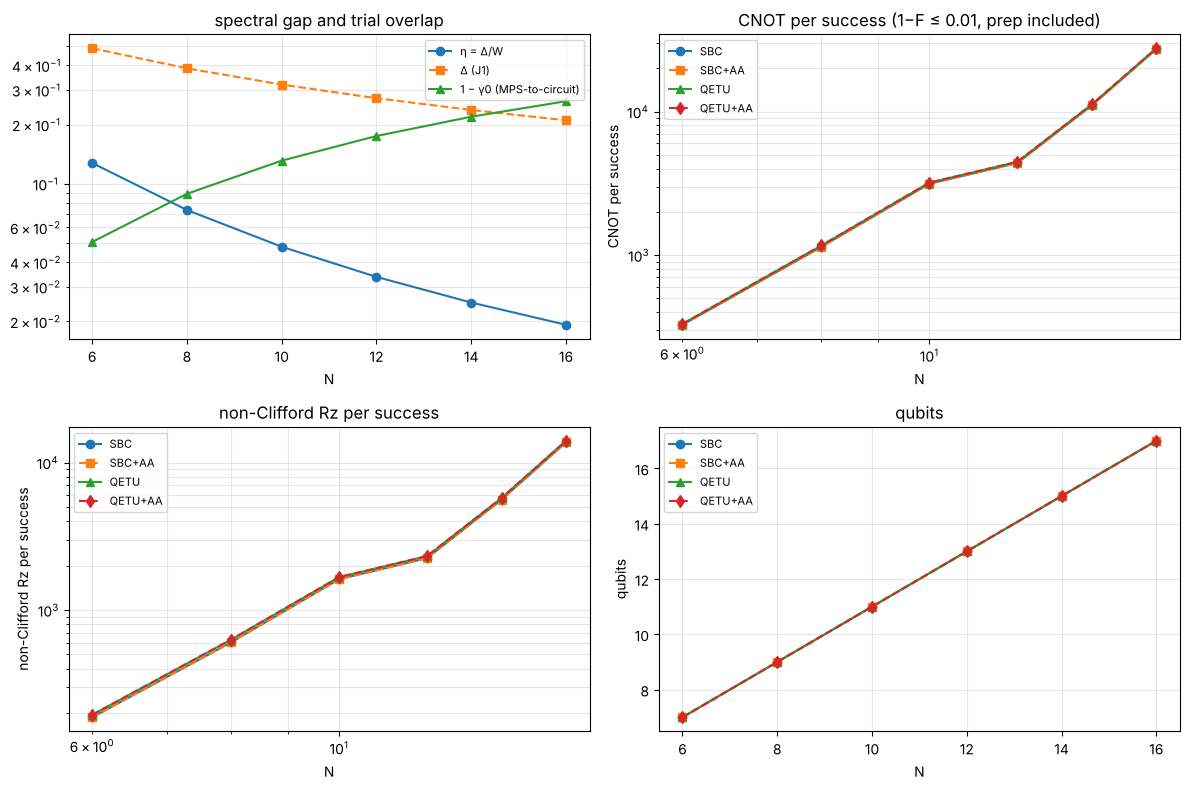

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0, 0].semilogy(prep.index, prep.eta, "o-", label="η = Δ/W")
ax[0, 0].semilogy(prep.index, prep.gap, "s--", label="Δ (J1)")
ax[0, 0].semilogy(prep.index, 1 - prep.gamma0, "^-", label="1 − γ0 (MPS-to-circuit)")
ax[0, 0].set(xlabel="N", title="spectral gap and trial overlap"); ax[0, 0].legend()
mk = dict(zip(METHODS, ["o-", "s--", "^-", "d--"]))
for name in METHODS:
    s = res[res.method == name]
    ax[0, 1].loglog(s.N, s.CNOT_per_success, mk[name], label=name)
    ax[1, 0].loglog(s.N, s.Rz_per_success, mk[name], label=name)
    ax[1, 1].plot(s.N, s.qubits, mk[name], label=name)
ax[0, 1].set(xlabel="N", ylabel="CNOT per success", title=f"CNOT per success (1−F ≤ {EPS}, prep included)")
ax[1, 0].set(xlabel="N", ylabel="non-Clifford Rz per success", title="non-Clifford Rz per success")
ax[1, 1].set(xlabel="N", ylabel="qubits", title="qubits")
for a in ax.ravel():
    a.grid(alpha=0.3, which="both"); a.legend(fontsize=8)
fig.tight_layout(); plt.show()